In [75]:
import pickle
from pathlib import Path

import pandas as pd
import yaml

config_path = Path("./config.yaml")
with config_path.open("r") as f:
    config = yaml.safe_load(f)

label_mode = "custom"  # "config" uses names from config.yaml, "custom" uses custom_labels
custom_labels = config.get(
    "custom_labels",
    {
        # "hygma": "HyGMA",
        # "hgnn_shared": "HGNN Shared",
        # "learned_affinity": "Learned Affinity",
        # "mlp_shared": "MLP Shared",
    },
)
plot_colors = config.get(
    "plot_colors",
    {
        # "hygma": "tab:blue",
        # "hgnn_shared": "tab:orange",
        # "learned_affinity": "#2ca02c",
        # "mlp_shared": "#d62728",
    },
)


def resolve_plot_label(plot_group):
    if label_mode == "config":
        return plot_group
    if label_mode != "custom":
        raise ValueError("label_mode must be either 'config' or 'custom'")

    if plot_group in custom_labels:
        return custom_labels[plot_group]

    experiment_name = plot_group.split("/", maxsplit=1)[-1]
    return custom_labels.get(experiment_name, plot_group)


def resolve_plot_color(plot_group):
    if plot_group in plot_colors:
        return plot_colors[plot_group]

    experiment_name = plot_group.split("/", maxsplit=1)[-1]
    return plot_colors.get(experiment_name)


def load_training_stats(stats_path):
    """Load a training-stats pickle, or return None if the file is truncated.

    The trainers save with a plain open(path, "wb") + pickle.dump, so a file
    read while a live run is mid-save is cut short. That raises
    UnpicklingError("pickle data was truncated"), or EOFError if it is empty.
    """
    try:
        with stats_path.open("rb") as f:
            return pickle.load(f)
    except (EOFError, pickle.UnpicklingError):
        return None


def load_reward_runs(batches):
    """Read the reward series of every configured experiment/trial in `batches`.

    Returns (runs, missing_paths, truncated_paths); each run is a DataFrame with
    total_steps / update / reward / batch / experiment / trial columns. `update`
    is the PPO update number (1, 2, ...): every stats row is one update, so it
    is the row position. Shared by the reward plots.
    """
    runs = []
    missing_paths = []
    truncated_paths = []

    for batch in batches:
        for experiment in config["experiments"]:
            for trial in config["trials"]:
                stats_path = (
                    base_path
                    / batch
                    / experiment
                    / trial
                    / "logs"
                    / "training_stats_checkpoint.pkl"
                )

                if not stats_path.exists():
                    missing_paths.append(str(stats_path))
                    continue

                training_stats = load_training_stats(stats_path)
                if training_stats is None:
                    truncated_paths.append(str(stats_path))
                    continue

                run_df = pd.DataFrame(
                    {
                        "total_steps": training_stats["total_steps"],
                        "update": range(1, len(training_stats["total_steps"]) + 1),
                        "reward": training_stats["reward"],
                    }
                )
                run_df["batch"] = batch
                run_df["experiment"] = experiment
                run_df["trial"] = trial
                runs.append(run_df)

    return runs, missing_paths, truncated_paths


def summarize_rewards(rewards_df, group_cols, x="total_steps"):
    """Mean and SEM of reward over trials, per group and x value.

    `x` is the x-axis column, total_steps (the default) or update. Trials are
    matched on exact x values, so runs whose step grids differ do not average
    together. Update numbers always match.
    """
    return (
        rewards_df.groupby([*group_cols, x], as_index=False)
        .agg(
            mean_reward=("reward", "mean"),
            sem_reward=(
                "reward",
                lambda s: s.std(ddof=1) / (len(s) ** 0.5) if len(s) > 1 else 0.0,
            ),
            n_runs=("reward", "size"),
        )
        .sort_values([*group_cols, x])
    )


base_path = Path(config["base_path"])
runs, missing_paths, truncated_paths = load_reward_runs(config["batches"])

if truncated_paths:
    print(f"Skipped {len(truncated_paths)} truncated pickle file(s):")
    for path in truncated_paths:
        print(f"  {path}")

if not runs:
    raise FileNotFoundError("No training stats files found for the configured runs")

all_rewards_df = pd.concat(runs, ignore_index=True)
all_rewards_df["plot_group"] = all_rewards_df["experiment"]
if all_rewards_df["batch"].nunique() > 1:
    all_rewards_df["plot_group"] = (
        all_rewards_df["batch"] + "/" + all_rewards_df["experiment"]
    )

reward_summary = summarize_rewards(all_rewards_df, ["plot_group"])

reward_summary["display_label"] = reward_summary["plot_group"].map(resolve_plot_label)
reward_summary["plot_color"] = reward_summary["plot_group"].map(resolve_plot_color)

print(f"Using '{label_mode}' labels for the legend.")

print(
    f"Loaded {len(runs)} run(s) across {all_rewards_df['batch'].nunique()} batch(es) and "
    f"{all_rewards_df['experiment'].nunique()} experiment(s)."
)
if missing_paths:
    print(f"Skipped {len(missing_paths)} missing run file(s).")

print(reward_summary)

max_runs = reward_summary["n_runs"].max()

# Count of all datapoints (anywhere) with max n_runs
count_with_max = reward_summary["n_runs"].eq(max_runs).sum()

if count_with_max > 0:
    current_total_steps_max = reward_summary.loc[
        reward_summary["n_runs"].eq(max_runs), "total_steps"
    ].max()
else:
    current_total_steps_max = None

# Count of leading datapoints from the start that all still have max n_runs (per plot group)
leading_with_max = (
    reward_summary.sort_values(["plot_group", "total_steps"])
    .groupby("plot_group")["n_runs"]
    .apply(lambda s: s.eq(max_runs).cummin().sum())
)

print(f"Completed datapoints {count_with_max}")
print(f"Completed steps {current_total_steps_max}")
print("Leading complete datapoints per line:")
print(leading_with_max)


# --- Data collected per trial / per experiment ---
# Data collected for a run = its furthest-reached total_steps.
per_trial_steps = (
    all_rewards_df.groupby(["batch", "experiment", "trial"], as_index=False)[
        "total_steps"
    ]
    .max()
    .rename(columns={"total_steps": "steps_collected"})
    .sort_values(["batch", "experiment", "trial"])
)

print("\nData collected per trial:")
for row in per_trial_steps.itertuples(index=False):
    print(
        f"  {row.batch}/{row.experiment}/{row.trial}: "
        f"{int(row.steps_collected):,} steps"
    )

per_experiment_steps = (
    per_trial_steps.groupby(["batch", "experiment"], as_index=False)
    .agg(total_steps=("steps_collected", "sum"), n_trials=("trial", "size"))
    .sort_values(["batch", "experiment"])
)

print("\nTotal data per experiment:")
for row in per_experiment_steps.itertuples(index=False):
    print(
        f"  {row.batch}/{row.experiment}: "
        f"{int(row.total_steps):,} steps across {int(row.n_trials)} trial(s)"
    )

print(f"\nGrand total: {int(per_trial_steps['steps_collected'].sum()):,} steps")

Using 'custom' labels for the legend.
Loaded 20 run(s) across 1 batch(es) and 2 experiment(s).
Skipped 22 missing run file(s).
     plot_group  total_steps  mean_reward    sem_reward  n_runs display_label  \
0     mappo_mlp         6400     0.035781  1.211752e-02      10     mappo_mlp   
1     mappo_mlp        12800     0.035781  1.211752e-02      10     mappo_mlp   
2     mappo_mlp        19200     0.035781  1.211752e-02      10     mappo_mlp   
3     mappo_mlp        25600     0.035781  1.211752e-02      10     mappo_mlp   
4     mappo_mlp        32000     0.035781  1.211752e-02      10     mappo_mlp   
...         ...          ...          ...           ...     ...           ...   
3119     rmappo      9971200     1.998750  1.087541e-03      10        rmappo   
3120     rmappo      9977600     1.998750  1.087541e-03      10        rmappo   
3121     rmappo      9984000     1.998750  1.087541e-03      10        rmappo   
3122     rmappo      9990400     1.998750  1.087541e-03      10

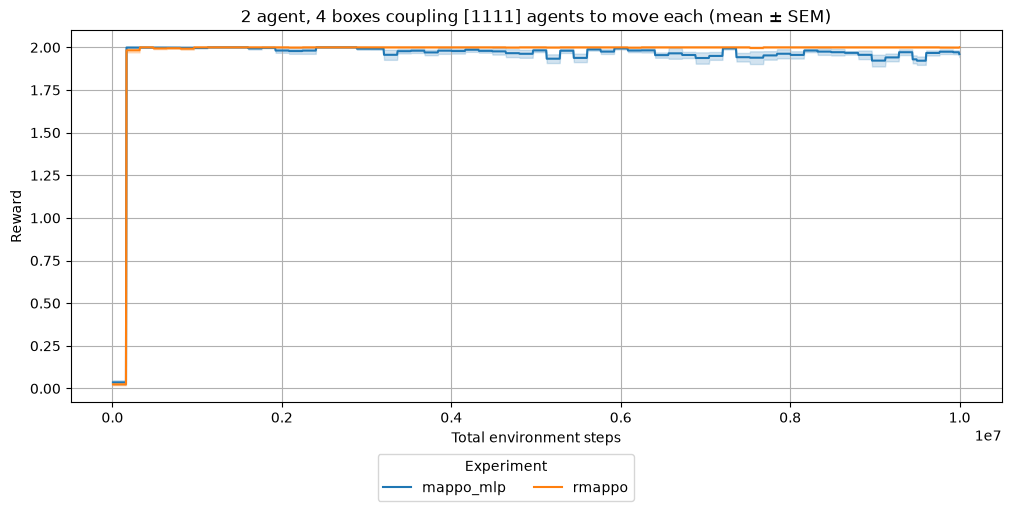

In [76]:
import matplotlib.pyplot as plt

# Constrained layout reserves room for a legend placed "outside" the axes, so
# the legend sits below the x-axis label instead of on top of the curves.
fig = plt.figure(figsize=(10, 5), layout="constrained")


for plot_group, group_df in reward_summary.groupby("plot_group"):
    group_df = group_df.sort_values("total_steps")
    x = group_df["total_steps"]
    y = group_df["mean_reward"]
    sem = group_df["sem_reward"]
    display_label = group_df["display_label"].iloc[0]
    plot_color = group_df["plot_color"].iloc[0]

    line_kwargs = {"label": display_label}
    if pd.notna(plot_color):
        line_kwargs["color"] = plot_color

    line, = plt.plot(x, y, **line_kwargs)
    plt.fill_between(x, y - sem, y + sem, alpha=0.2, color=line.get_color())

plt.xlabel("Total environment steps")
plt.ylabel("Reward")
plt.title("2 agent, 4 boxes coupling [1111] agents to move each (mean ± SEM)")
plt.grid(True)
fig.legend(title="Experiment", loc="outside lower center", ncol=3)
plt.show()

Trials per batch (rows) and experiment (columns):
experiment               rmappo  mappo_mlp
batch                                     
rover_2poi_c2                10         10
rover_2poi_c8                10         10
rover_4poi_c1234             10         10
rover_6poi_c3_ring           10         10
rover_6poi_c8-4-4-8-4-4      10         10


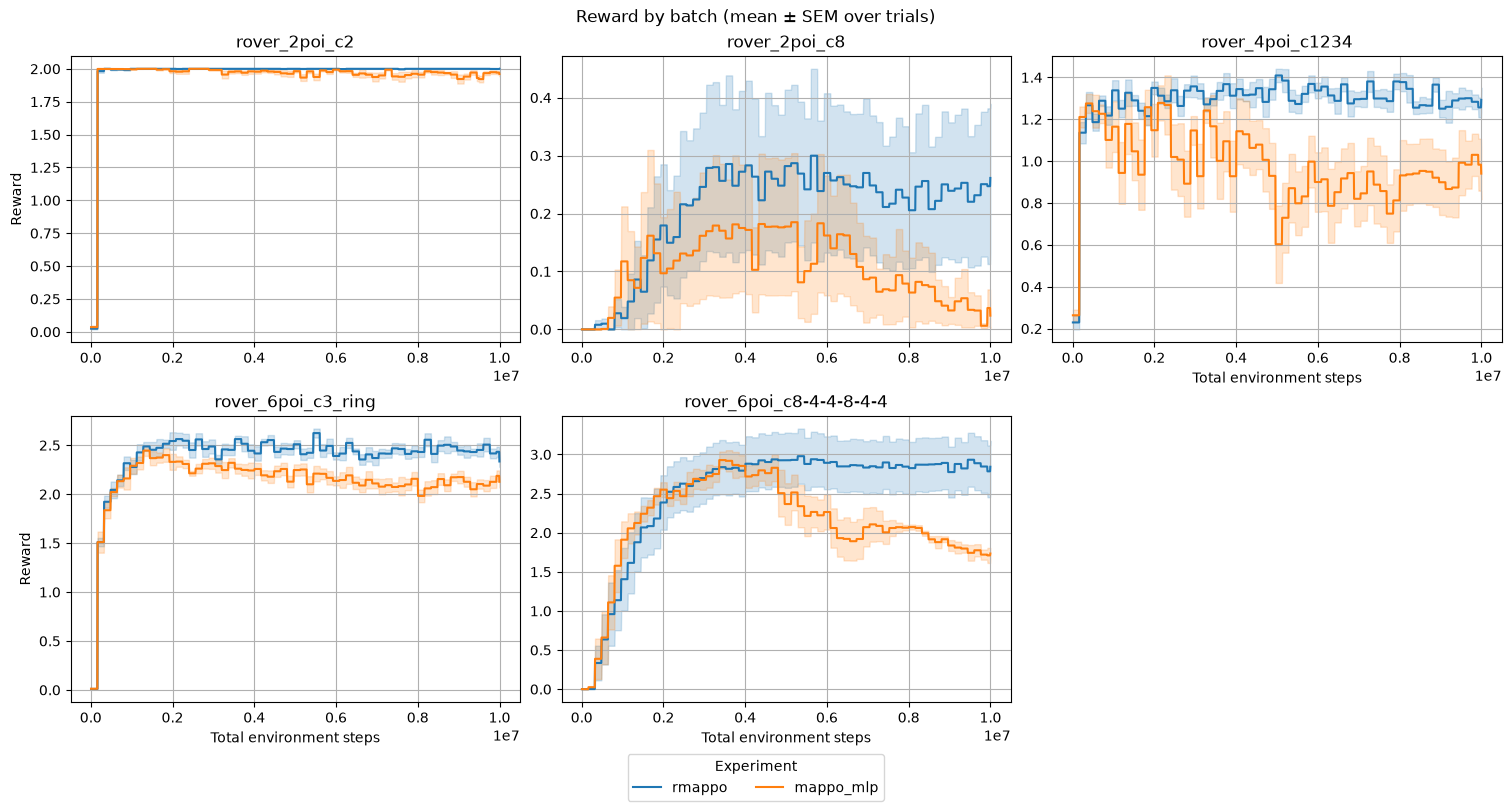

In [77]:
import math

# --- Reward curves: one subplot per batch, one shared legend ----------------
# Every subplot shows the same experiments (config["experiments"]) on a
# different batch (config["multi_batches"]). Each experiment keeps one color in
# every subplot, so a single figure-level legend is valid for all of them.
# Y axes are NOT shared: reward scales differ between batches.

multi_batches = config.get("multi_batches") or []

if not multi_batches:
    print("No 'multi_batches' in config.yaml -- skipping the multi-batch reward plot.")
else:
    mb_runs, _, mb_truncated_paths = load_reward_runs(multi_batches)
    if mb_truncated_paths:
        for truncated_path in mb_truncated_paths:
            print(f"Skipped {truncated_path} truncated pickle file(s).")
    if not mb_runs:
        raise FileNotFoundError("No training stats files found for multi_batches")

    mb_rewards_df = pd.concat(mb_runs, ignore_index=True)
    mb_summary = summarize_rewards(mb_rewards_df, ["batch", "experiment"])

    # Trials found per (batch, experiment). A band from a single trial has
    # zero width, so check this before reading the SEM.
    print("Trials per batch (rows) and experiment (columns):")
    print(
        mb_rewards_df.groupby(["batch", "experiment"])["trial"]
        .nunique()
        .unstack(fill_value=0)
        .reindex(index=multi_batches, columns=config["experiments"], fill_value=0)
        .to_string()
    )

    # One color per experiment, fixed by its position in config["experiments"],
    # so a missing experiment in one batch cannot shift the others' colors.
    # plot_colors overrides by experiment name; a "batch/experiment" key does
    # not apply here, because the shared legend needs one color per experiment.
    experiment_colors = {
        experiment: resolve_plot_color(experiment) or f"C{i % 10}"
        for i, experiment in enumerate(config["experiments"])
    }
    n_cols = math.ceil(math.sqrt(len(multi_batches)))
    n_rows = math.ceil(len(multi_batches) / n_cols)
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(5 * n_cols, 4 * n_rows),
        squeeze=False,
        layout="constrained",
    )

    legend_handles = {}
    for k, (ax, batch) in enumerate(zip(axes.flat, multi_batches)):
        batch_df = mb_summary[mb_summary["batch"] == batch]
        for experiment in config["experiments"]:
            group_df = batch_df[batch_df["experiment"] == experiment]
            if group_df.empty:
                continue
            x = group_df["total_steps"]
            y = group_df["mean_reward"]
            sem = group_df["sem_reward"]
            color = experiment_colors[experiment]

            line, = ax.plot(x, y, color=color)
            ax.fill_between(x, y - sem, y + sem, alpha=0.2, color=color)
            legend_handles.setdefault(experiment, line)

        if batch_df.empty:
            ax.text(0.5, 0.5, "no data", transform=ax.transAxes, ha="center", va="center")
        ax.set_title(resolve_plot_label(batch))
        ax.grid(True)
        # Axis labels per subplot, not fig.supxlabel: under constrained layout
        # the supxlabel collides with the legend placed outside below the grid.
        if k % n_cols == 0:
            ax.set_ylabel("Reward")
        if k + n_cols >= len(multi_batches):  # lowest subplot in its column
            ax.set_xlabel("Total environment steps")

    # Grid cells left over when len(multi_batches) is not a multiple of n_cols.
    for ax in axes.flat[len(multi_batches):]:
        ax.set_visible(False)

    legend_experiments = [e for e in config["experiments"] if e in legend_handles]
    fig.suptitle("Reward by batch (mean ± SEM over trials)")
    fig.legend(
        [legend_handles[e] for e in legend_experiments],
        [resolve_plot_label(e) for e in legend_experiments],
        title="Experiment",
        loc="outside lower center",
        ncol=3,
    )
    plt.show()

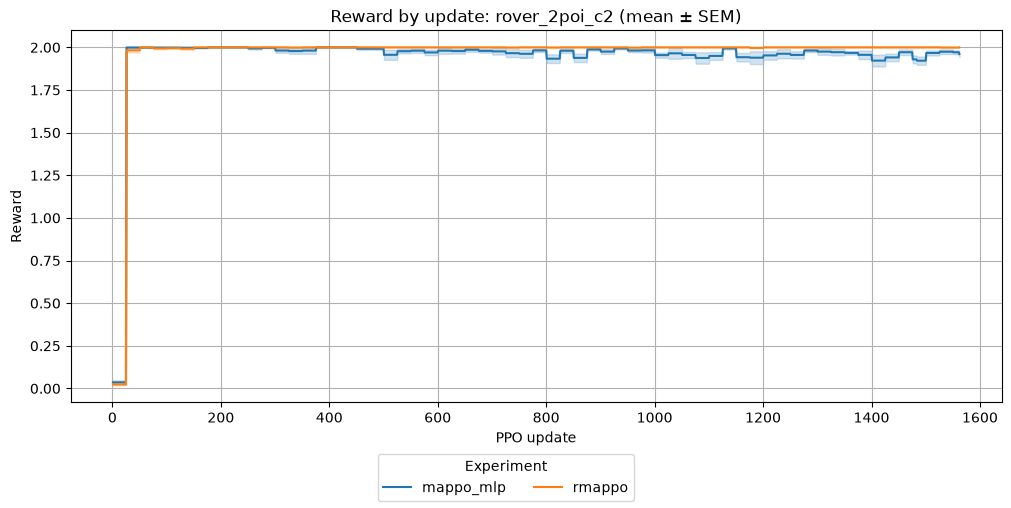

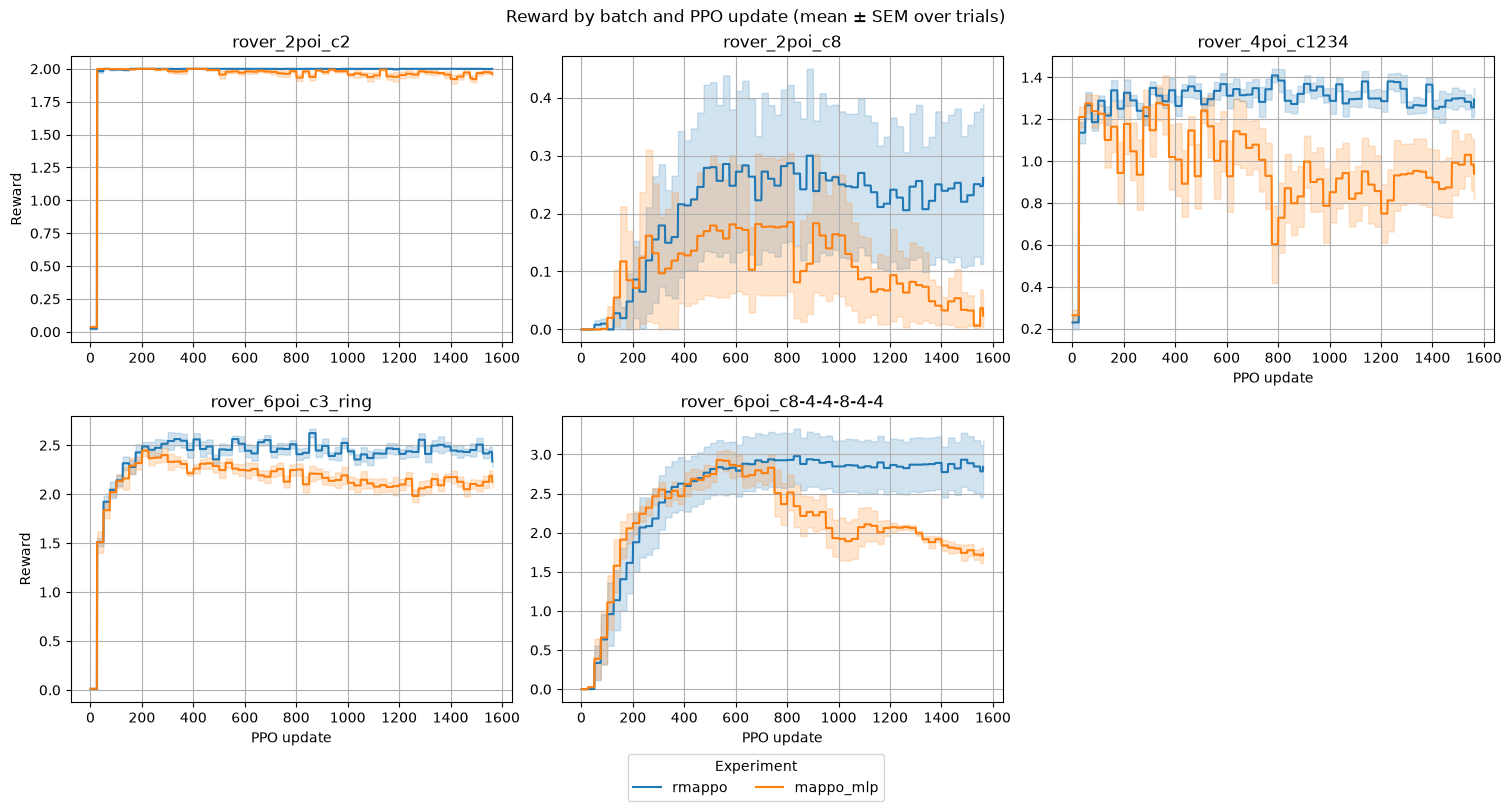

In [78]:
import math

import matplotlib.pyplot as plt

# --- Reward curves against the number of PPO updates ------------------------
# The two reward figures above (every `batches` entry on one axis, then one
# subplot per `multi_batches` entry), with the update number on the x axis
# instead of total_steps. Every stats row is one update and neither total_steps
# nor reward is ever NaN-padded, so `load_reward_runs` takes the row position
# as the update number. That holds for resumed runs too.
#
# Why: arms can spend different amounts of the step budget on one update. The
# `_n96` groups take ~3x the env steps per update, and intervention runs trained
# before the 2026-10-12 fixed-batch redesign appended their fork steps on top of
# a full rollout (986 updates at 2a/4o, 422 at 6a/4o, against ~2960 for the
# parent). This view matches arms on optimizer steps, not on data, so read it
# next to the step-based one.


def draw_reward_curve(ax, summary, color=None, label=None):
    """Mean reward line and ± SEM band of one group, against the update number."""
    summary = summary.sort_values("update")
    x, y, sem = summary["update"], summary["mean_reward"], summary["sem_reward"]
    line_kwargs = {"label": label}
    if color is not None and pd.notna(color):
        line_kwargs["color"] = color
    line, = ax.plot(x, y, **line_kwargs)
    ax.fill_between(x, y - sem, y + sem, alpha=0.2, color=line.get_color())
    return line


# Every batch in config["batches"] on one axis.
update_summary = summarize_rewards(all_rewards_df, ["plot_group"], x="update")
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for plot_group, group_df in update_summary.groupby("plot_group"):
    draw_reward_curve(
        ax, group_df, resolve_plot_color(plot_group), resolve_plot_label(plot_group)
    )
ax.set_xlabel("PPO update")
ax.set_ylabel("Reward")
ax.set_title(f"Reward by update: {', '.join(config['batches'])} (mean ± SEM)")
ax.grid(True)
fig.legend(title="Experiment", loc="outside lower center", ncol=3)
plt.show()

# One subplot per batch in config["multi_batches"], one shared legend. Colors
# and layout follow the step-based grid above.
multi_batches = config.get("multi_batches") or []

if not multi_batches:
    print("No 'multi_batches' in config.yaml -- skipping the multi-batch plot by update.")
else:
    mb_runs, _, mb_truncated_paths = load_reward_runs(multi_batches)
    if mb_truncated_paths:
        print(f"Skipped {len(mb_truncated_paths)} truncated pickle file(s).")
    if not mb_runs:
        raise FileNotFoundError("No training stats files found for multi_batches")

    mb_update_summary = summarize_rewards(
        pd.concat(mb_runs, ignore_index=True), ["batch", "experiment"], x="update"
    )

    experiment_colors = {
        experiment: resolve_plot_color(experiment) or f"C{i % 10}"
        for i, experiment in enumerate(config["experiments"])
    }
    n_cols = math.ceil(math.sqrt(len(multi_batches)))
    n_rows = math.ceil(len(multi_batches) / n_cols)
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(5 * n_cols, 4 * n_rows),
        squeeze=False,
        layout="constrained",
    )

    legend_handles = {}
    for k, (ax, batch) in enumerate(zip(axes.flat, multi_batches)):
        batch_df = mb_update_summary[mb_update_summary["batch"] == batch]
        for experiment in config["experiments"]:
            group_df = batch_df[batch_df["experiment"] == experiment]
            if group_df.empty:
                continue
            line = draw_reward_curve(ax, group_df, experiment_colors[experiment])
            legend_handles.setdefault(experiment, line)

        if batch_df.empty:
            ax.text(0.5, 0.5, "no data", transform=ax.transAxes, ha="center", va="center")
        ax.set_title(resolve_plot_label(batch))
        ax.grid(True)
        if k % n_cols == 0:
            ax.set_ylabel("Reward")
        if k + n_cols >= len(multi_batches):  # lowest subplot in its column
            ax.set_xlabel("PPO update")

    # Grid cells left over when len(multi_batches) is not a multiple of n_cols.
    for ax in axes.flat[len(multi_batches):]:
        ax.set_visible(False)

    legend_experiments = [e for e in config["experiments"] if e in legend_handles]
    fig.suptitle("Reward by batch and PPO update (mean ± SEM over trials)")
    fig.legend(
        [legend_handles[e] for e in legend_experiments],
        [resolve_plot_label(e) for e in legend_experiments],
        title="Experiment",
        loc="outside lower center",
        ncol=3,
    )
    plt.show()

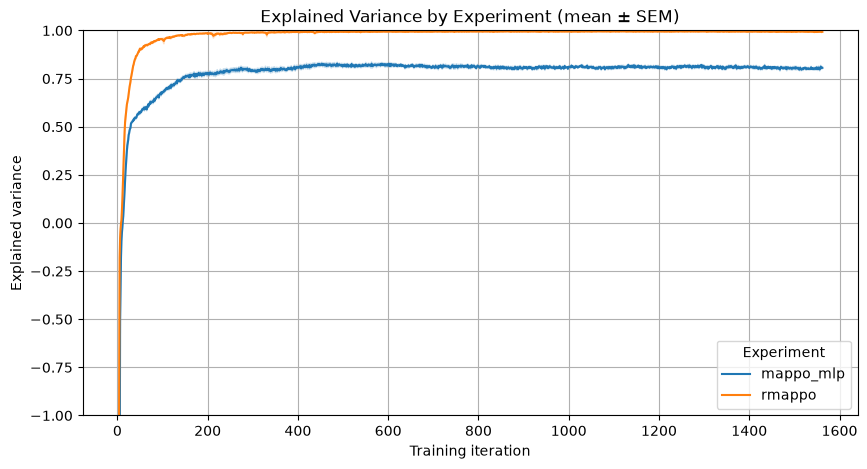

In [79]:
ev_runs = []
ev_missing_paths = []

for batch in config["batches"]:
    for experiment in config["experiments"]:
        for trial in config["trials"]:
            stats_path = (
                base_path
                / batch
                / experiment
                / trial
                / "logs"
                / "training_stats_checkpoint.pkl"
            )

            if not stats_path.exists():
                ev_missing_paths.append(str(stats_path))
                continue

            with stats_path.open("rb") as f:
                training_stats = pickle.load(f)

            explained_variance = training_stats.get("explained_variance")
            if explained_variance is None or len(explained_variance) == 0:
                continue

            ev_df = pd.DataFrame(
                {
                    "iteration": range(1, len(explained_variance) + 1),
                    "explained_variance": explained_variance,
                }
            )
            ev_df["batch"] = batch
            ev_df["experiment"] = experiment
            ev_df["trial"] = trial
            ev_runs.append(ev_df)

if not ev_runs:
    raise FileNotFoundError(
        "No explained_variance data found for the configured runs"
    )

all_ev_df = pd.concat(ev_runs, ignore_index=True)
all_ev_df["plot_group"] = all_ev_df["experiment"]
if all_ev_df["batch"].nunique() > 1:
    all_ev_df["plot_group"] = (
        all_ev_df["batch"] + "/" + all_ev_df["experiment"]
    )

ev_summary = (
    all_ev_df.groupby(["plot_group", "iteration"], as_index=False)
    .agg(
        mean_ev=("explained_variance", "mean"),
        sem_ev=(
            "explained_variance",
            lambda s: s.std(ddof=1) / (len(s) ** 0.5) if len(s) > 1 else 0.0,
        ),
        n_runs=("explained_variance", "size"),
    )
    .sort_values(["plot_group", "iteration"])
)

ev_summary["display_label"] = ev_summary["plot_group"].map(resolve_plot_label)
ev_summary["plot_color"] = ev_summary["plot_group"].map(resolve_plot_color)

plt.figure(figsize=(10, 5))

for plot_group, group_df in ev_summary.groupby("plot_group"):
    group_df = group_df.sort_values("iteration")
    x = group_df["iteration"]
    y = group_df["mean_ev"]
    sem = group_df["sem_ev"]
    display_label = group_df["display_label"].iloc[0]
    plot_color = group_df["plot_color"].iloc[0]

    line_kwargs = {"label": display_label}
    if pd.notna(plot_color):
        line_kwargs["color"] = plot_color

    line, = plt.plot(x, y, **line_kwargs)
    plt.fill_between(x, y - sem, y + sem, alpha=0.2, color=line.get_color())

plt.xlabel("Training iteration")
plt.ylabel("Explained variance")
plt.ylim([-1,1])
plt.title("Explained Variance by Experiment (mean ± SEM)")
plt.grid(True)
plt.legend(title="Experiment")
plt.show()


In [80]:
gl_runs = []
gl_missing_paths = []

for batch in config["batches"]:
    for experiment in config["experiments"]:
        for trial in config["trials"]:
            stats_path = (
                base_path
                / batch
                / experiment
                / trial
                / "logs"
                / "training_stats_checkpoint.pkl"
            )

            if not stats_path.exists():
                gl_missing_paths.append(str(stats_path))
                continue

            with stats_path.open("rb") as f:
                training_stats = pickle.load(f)

            grouping_loss = training_stats.get("grouping_loss")
            if grouping_loss is None or len(grouping_loss) == 0:
                continue

            gl_df = pd.DataFrame(
                {
                    "iteration": range(1, len(grouping_loss) + 1),
                    "grouping_loss": grouping_loss,
                }
            )
            gl_df["batch"] = batch
            gl_df["experiment"] = experiment
            gl_df["trial"] = trial
            gl_runs.append(gl_df)

if not gl_runs:
    raise FileNotFoundError(
        "No grouping_loss data found for the configured runs"
    )

all_gl_df = pd.concat(gl_runs, ignore_index=True)
all_gl_df["plot_group"] = all_gl_df["experiment"]
if all_gl_df["batch"].nunique() > 1:
    all_gl_df["plot_group"] = (
        all_gl_df["batch"] + "/" + all_gl_df["experiment"]
    )

gl_summary = (
    all_gl_df.groupby(["plot_group", "iteration"], as_index=False)
    .agg(
        mean_gl=("grouping_loss", "mean"),
        sem_gl=(
            "grouping_loss",
            lambda s: s.std(ddof=1) / (len(s) ** 0.5) if len(s) > 1 else 0.0,
        ),
        n_runs=("grouping_loss", "size"),
    )
    .sort_values(["plot_group", "iteration"])
)

gl_summary["display_label"] = gl_summary["plot_group"].map(resolve_plot_label)
gl_summary["plot_color"] = gl_summary["plot_group"].map(resolve_plot_color)

plt.figure(figsize=(10, 5))

for plot_group, group_df in gl_summary.groupby("plot_group"):
    group_df = group_df.sort_values("iteration")
    x = group_df["iteration"]
    y = group_df["mean_gl"]
    sem = group_df["sem_gl"]
    display_label = group_df["display_label"].iloc[0]
    plot_color = group_df["plot_color"].iloc[0]

    line_kwargs = {"label": display_label}
    if pd.notna(plot_color):
        line_kwargs["color"] = plot_color

    line, = plt.plot(x, y, **line_kwargs)
    plt.fill_between(x, y - sem, y + sem, alpha=0.2, color=line.get_color())

plt.xlabel("Training iteration")
plt.ylabel("Grouping loss")
plt.title("Grouping Loss by Experiment (mean ± SEM)")
plt.grid(True)
plt.legend(title="Experiment")
plt.show()


FileNotFoundError: No grouping_loss data found for the configured runs

In [ ]:
import sys

import numpy as np

# Try to label action indices with the HRL skill names; fall back to indices.
try:
    repo_root = Path.cwd().parent
    if str(repo_root) not in sys.path:
        sys.path.insert(0, str(repo_root))
    from algorithms.hierarchical.skills import SKILL_ORDER
except Exception:
    SKILL_ORDER = None


def action_label(idx, n_actions):
    if SKILL_ORDER is not None and n_actions == len(SKILL_ORDER):
        return SKILL_ORDER[idx]
    return f"action {idx}"


ad_runs = []

for batch in config["batches"]:
    for experiment in config["experiments"]:
        for trial in config["trials"]:
            stats_path = (
                base_path
                / batch
                / experiment
                / trial
                / "logs"
                / "training_stats_checkpoint.pkl"
            )

            if not stats_path.exists():
                continue

            with stats_path.open("rb") as f:
                training_stats = pickle.load(f)

            action_distribution = training_stats.get("action_distribution")
            if not action_distribution:
                continue

            # action_distribution is one fractions-vector per recorded iteration.
            dist = np.asarray(action_distribution, dtype=float)  # (n_iter, n_actions)
            n_iter, n_actions = dist.shape

            ad_df = pd.DataFrame(dist, columns=range(n_actions))
            ad_df["iteration"] = range(1, n_iter + 1)
            ad_df = ad_df.melt(
                id_vars="iteration", var_name="action", value_name="fraction"
            )
            ad_df["batch"] = batch
            ad_df["experiment"] = experiment
            ad_df["trial"] = trial
            ad_runs.append(ad_df)

if not ad_runs:
    raise FileNotFoundError(
        "No action_distribution data found for the configured runs "
        "(only recorded for discrete-action envs)."
    )

all_ad_df = pd.concat(ad_runs, ignore_index=True)
all_ad_df["plot_group"] = all_ad_df["experiment"]
if all_ad_df["batch"].nunique() > 1:
    all_ad_df["plot_group"] = (
        all_ad_df["batch"] + "/" + all_ad_df["experiment"]
    )

# Mean fraction per action over training iterations, averaged across trials.
ad_summary = (
    all_ad_df.groupby(["plot_group", "iteration", "action"], as_index=False)
    .agg(mean_fraction=("fraction", "mean"))
    .sort_values(["plot_group", "iteration", "action"])
)

plot_groups = sorted(ad_summary["plot_group"].unique())
fig, axes = plt.subplots(
    len(plot_groups),
    1,
    figsize=(10, 4 * len(plot_groups)),
    squeeze=False,
)

for ax, plot_group in zip(axes[:, 0], plot_groups):
    group_df = ad_summary[ad_summary["plot_group"] == plot_group]
    pivot = group_df.pivot(
        index="iteration", columns="action", values="mean_fraction"
    ).sort_index()
    n_actions = pivot.shape[1]
    labels = [action_label(a, n_actions) for a in pivot.columns]

    ax.stackplot(pivot.index, pivot.T.values, labels=labels, alpha=0.85)
    ax.set_xlim(pivot.index.min(), pivot.index.max())
    ax.set_ylim(0, 1)
    ax.set_xlabel("Training iteration")
    ax.set_ylabel("Action fraction")
    ax.set_title(f"{resolve_plot_label(plot_group)} — action distribution (mean over trials)")
    ax.legend(loc="upper right", ncol=n_actions, fontsize="small")

fig.tight_layout()
plt.show()


In [ ]:
# --- Goal-usefulness diagnostics ------------------------------------------
# One parameterized plotter instead of another copy-pasted per-metric cell.
#
# Plots against total_steps, NOT the index-based "iteration" the cells above
# use: a series that started late (a metric added mid-run, or one absent from
# the checkpoint a run resumed from) is left-padded with NaN by
# TrainingStatsTracker.to_dict(), so index k means the same training step in
# every run only when it is read against total_steps.
#
# READING ORDER for these series (this is the finding, not a detail):
#   d_cos_gap_env  FIRST. If it sits at ~0 the manager's goals do not depend on
#                  the state, and d_cos_gap_agent is uninterpretable however
#                  large it is -- a fixed per-agent code scores well on it while
#                  doing nothing the hierarchy exists for.
#   eval_gap_*     asymmetric. ~0 is STRONG evidence the goals do not matter;
#                  >0 is WEAK evidence they do, and its size is not "the value
#                  of hierarchy" (a permuted rollout is off-policy twice).

def plot_series(keys, ylabel, title, x="total_steps", stats_file="training_stats_checkpoint.pkl"):
    runs = []
    for batch in config["batches"]:
        for experiment in config["experiments"]:
            for trial in config["trials"]:
                stats_path = base_path / batch / experiment / trial / "logs" / stats_file
                if not stats_path.exists():
                    continue
                with stats_path.open("rb") as f:
                    training_stats = pickle.load(f)
                steps = training_stats.get(x)
                for key in keys:
                    series = training_stats.get(key)
                    if series is None or len(series) == 0 or steps is None:
                        continue
                    n = min(len(series), len(steps))
                    df = pd.DataFrame({x: steps[:n], "value": series[:n]})
                    df["series"] = key
                    df["batch"], df["experiment"], df["trial"] = batch, experiment, trial
                    runs.append(df)

    if not runs:
        # The normal state right after a new diagnostic lands: warn, don't raise.
        print(f"No data for {keys} in the configured runs -- nothing to plot.")
        return

    all_df = pd.concat(runs, ignore_index=True).dropna(subset=["value"])
    if all_df.empty:
        print(f"All values NaN for {keys} (recorded but never evaluated yet).")
        return

    all_df["plot_group"] = all_df["experiment"]
    if all_df["batch"].nunique() > 1:
        all_df["plot_group"] = all_df["batch"] + "/" + all_df["experiment"]
    all_df["plot_group"] = all_df["plot_group"] + " | " + all_df["series"]

    summary = (
        all_df.groupby(["plot_group", x], as_index=False)
        .agg(
            mean_v=("value", "mean"),
            sem_v=("value", lambda s: s.std(ddof=1) / (len(s) ** 0.5) if len(s) > 1 else 0.0),
            n_runs=("value", "size"),
        )
        .sort_values(["plot_group", x])
    )

    plt.figure(figsize=(10, 5))
    for plot_group, group_df in summary.groupby("plot_group"):
        group_df = group_df.sort_values(x)
        xs, ys, sem = group_df[x], group_df["mean_v"], group_df["sem_v"]
        line, = plt.plot(xs, ys, label=plot_group)
        plt.fill_between(xs, ys - sem, ys + sem, alpha=0.2, color=line.get_color())

    plt.axhline(0.0, color="0.6", lw=0.8, ls="--", zorder=0)
    plt.xlabel("Total environment steps")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# Behavioural: does the return depend on each worker getting ITS OWN goal?
# Read eval_gap_constant NEXT TO eval_gap_zeroed: constant ~ 0 with zeroed
# large means the manager is decorative (one frozen vector reproduces it).
plot_series(
    ["eval_gap_permuted", "eval_gap_constant", "eval_gap_zeroed"],
    "Return gap vs. real goals",
    "Goal-ablation eval gap (>0 = real goals help)",
)

# Is the manager->worker channel even connected? (FiLM arms)
# gamma/beta are zero-init and bias-free, so 0.0 is a KNOWN floor and a
# zero_goal arm reads exactly 0.0. Large gain with a flat eval gap means
# the channel is open and the behaviour it drives is task-irrelevant.
plot_series(
    ["worker_film_gain_rms", "worker_film_shift_ratio"],
    "FiLM goal influence",
    "modulation magnitude (0 = goal disconnected)",
)

plot_series(
    ["worker_goal_action_delta", "worker_tanh_saturation"],
    "Worker goal sensitivity / trunk saturation",
    "fraction",
)

# Latent: is d_cos above its own permutation nulls?
plot_series(
    ["d_cos_mean", "d_cos_null_agent", "d_cos_null_env"],
    "d_cos",
    "Manager transition cosine vs. its permutation nulls",
)
